 Working with Logistic Regression – Banking Dataset
Problem: A bank wants to predict whether a customer will subscribe to a term deposit (y = 1) or not (y = 0) based on customer information and marketing campaign attributes.


Dataset description
- y is the target column: 1 = subscribed, 0 = not subscribed.
- The other 20 columns are input features.
- This dataset contains numeric and categorical features. Categorical features must be encoded before Logistic Regression can use them.
- Important: duration is the length of the last contact. It may not be known before a call starts. If the goal is to predict subscription before contacting the customer, remove duration to avoid using information that would not yet be available.

Step 1: Import Python libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from sklearn.calibration import calibration_curve

import joblib


Step 2: Load the Banking dataset

In [ ]:
dt = pd.read_csv("banking.csv")


Step 3: Dataset description / quick data check

In [ ]:
# 1. Display the dataset
dt


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,59,retired,married,high.school,unknown,no,yes,telephone,jun,thu,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.866,5228.1,0
41184,31,housemaid,married,basic.4y,unknown,no,no,telephone,may,thu,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,0
41185,42,admin.,single,university.degree,unknown,yes,yes,telephone,may,wed,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
41186,48,technician,married,professional.course,no,no,yes,telephone,oct,tue,...,2,999,0,nonexistent,-3.4,92.431,-26.9,0.742,5017.5,0


In [ ]:
# 2. Display the first five rows
dt.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [ ]:
# 3. Display the number of rows and columns
dt.shape


(41188, 21)

In [ ]:
# 4. Display column names, data types, and non-null counts
dt.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 non-null 

In [ ]:
# 5. Statistical description of numeric columns
dt.describe()


,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911,0.112654
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528,0.316173
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000,0.000000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000,0.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,0.000000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,1.000000


In [ ]:
# 6. Check missing values in each column
dt.isnull().sum()


,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
# 7. Check the distribution of the target column
print("Target value counts:\n", dt["y"].value_counts())
print("\nTarget percentages:\n", (dt["y"].value_counts(normalize=True) * 100).round(2))


Target value counts:
 y
0    36548
1     4640
Name: count, dtype: int64

Target percentages:
 y
0    88.73
1    11.27
Name: proportion, dtype: float64


Step 4: Exploratory Data Analysis (brief)

In [ ]:
# Identify numeric and categorical columns
numeric_features = dt.drop(columns=["y"]).select_dtypes(include=np.number).columns.tolist()
categorical_features = dt.drop(columns=["y"]).select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)


Numeric features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


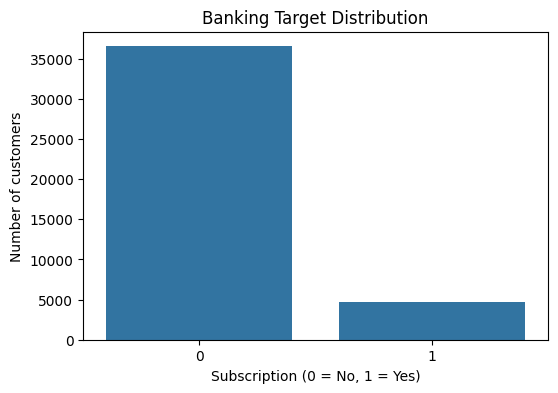

In [ ]:
# Plot the target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=dt, x="y")
plt.title("Banking Target Distribution")
plt.xlabel("Subscription (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.show()


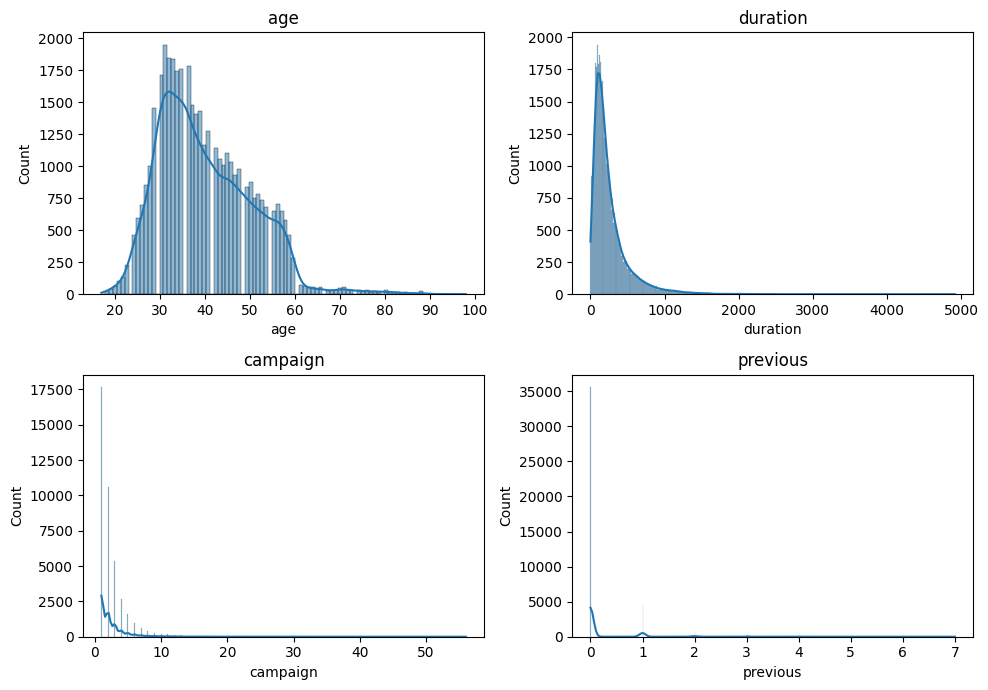

In [ ]:
# Plot distributions of selected numeric features
selected_numeric = ["age", "duration", "campaign", "previous"]

plt.figure(figsize=(10, 7))
for i, col in enumerate(selected_numeric, 1):
    plt.subplot(2, 2, i)
    sns.histplot(dt[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()


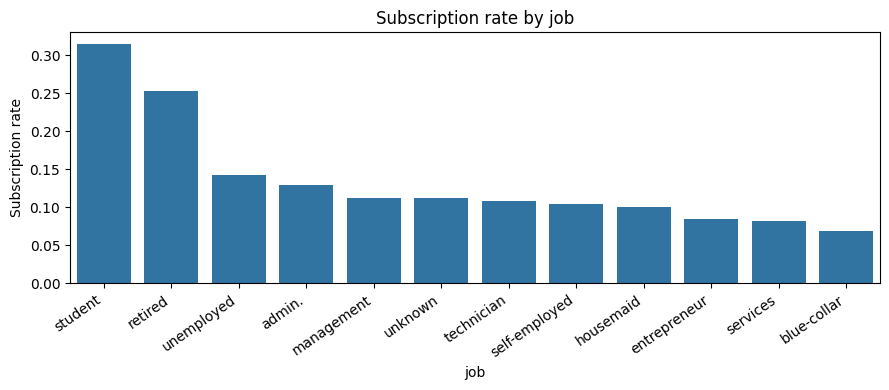

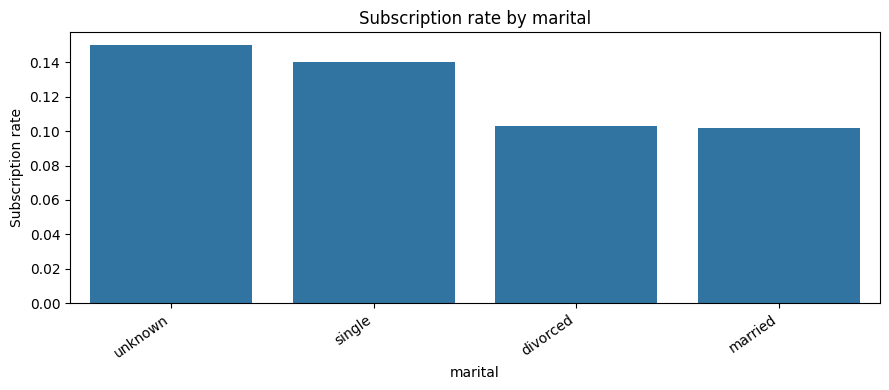

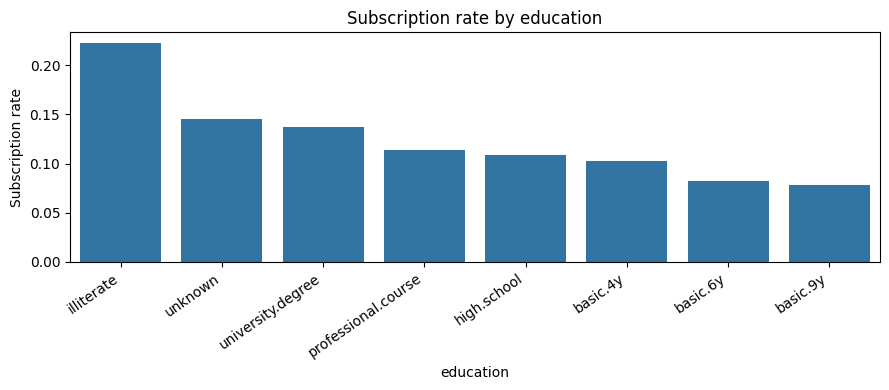

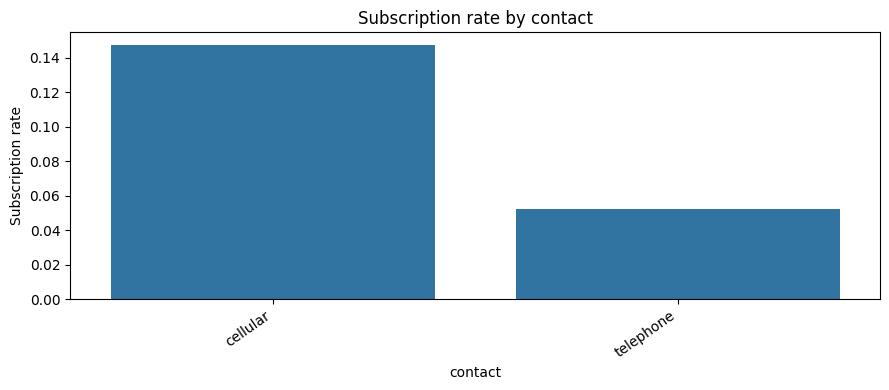

In [ ]:
# Compare subscription rates across selected categorical features
for col in ["job", "marital", "education", "contact"]:
    rate = dt.groupby(col, observed=False)["y"].mean().sort_values(ascending=False)
    plt.figure(figsize=(9, 4))
    sns.barplot(x=rate.index, y=rate.values)
    plt.title(f"Subscription rate by {col}")
    plt.ylabel("Subscription rate")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


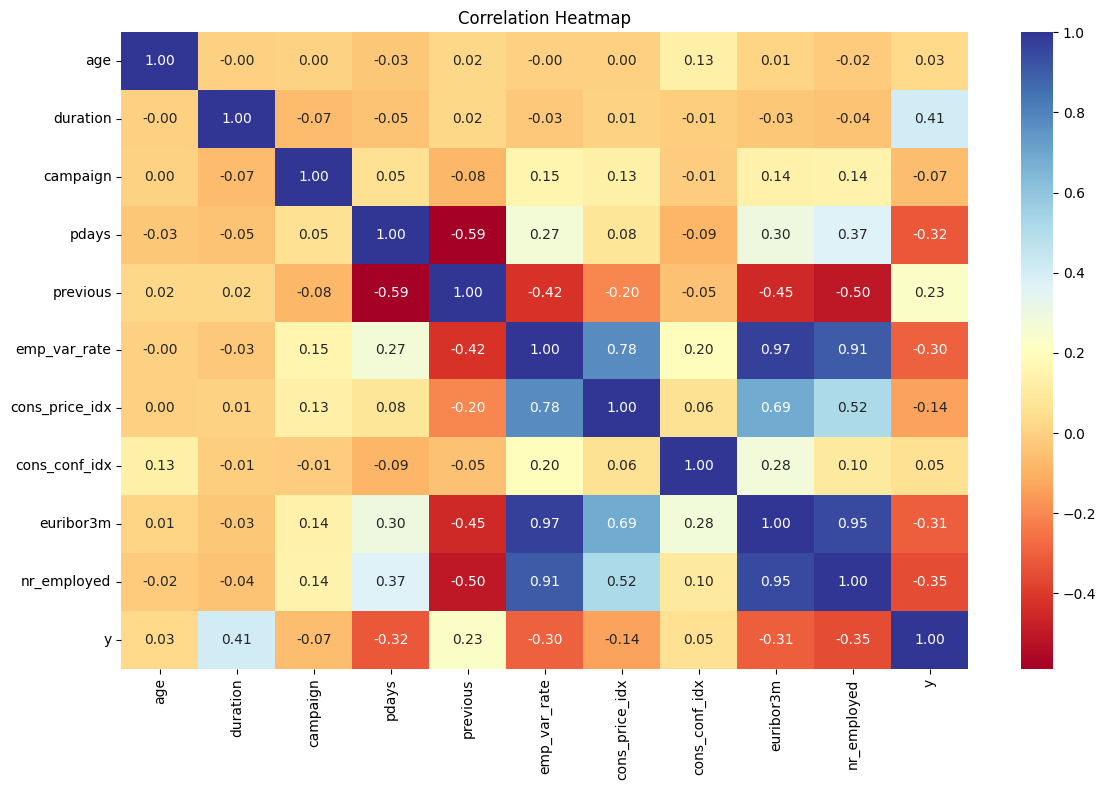

In [ ]:
# Correlation heatmap for numeric columns, including the target
plt.figure(figsize=(12, 8))
sns.heatmap(dt.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="RdYlBu")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


Step 5: Feature selection

In [ ]:
# Select input features (X) and target (y)
X = dt.drop("y", axis=1)
y = dt["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (41188, 20)
y shape: (41188,)


Step 6: Split data into training and testing sets

In [ ]:
# 70% training data and 30% testing data
# stratify=y preserves the target class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining target distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:\n", y_test.value_counts(normalize=True).round(3))


Training set: (28831, 20)
Testing set: (12357, 20)

Training target distribution:
 y
0    0.887
1    0.113
Name: proportion, dtype: float64

Testing target distribution:
 y
0    0.887
1    0.113
Name: proportion, dtype: float64


Step 7: Feature preprocessing and scaling

The Banking dataset has both numeric and categorical columns.
- Numeric features: fill missing values with the median, then standardize with StandardScaler.
- Categorical features: fill missing values with the most frequent value, then convert categories into numeric indicator columns using OneHotEncoder.
The preprocessing is placed inside a Pipeline and fitted on training data only. This prevents data leakage from the test set.

In [ ]:
# Re-identify columns from X
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Numeric preprocessing: median imputation -> standard scaling
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: most-frequent imputation -> one-hot encoding
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


Step 8: Train the Logistic Regression model

In [ ]:
# Combine preprocessing and Logistic Regression into one pipeline
clf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

# Train the complete pipeline using training data
clf_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'duration',
                                                   'campaign', 'pdays',
                                                   'previous', 'emp_var_rate',
                                                   'cons_price_idx',
                                                   'cons_conf_idx', 'euribor3m',
                                                   'nr_employed']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42, solver='liblinear'))])

Explanation:
- Pipeline joins preprocessing and model training into one workflow.
- class_weight="balanced" gives more weight to the minority class.
- max_iter=2000 allows more optimization iterations.
- fit() learns the preprocessing parameters and Logistic Regression coefficients from the training set.

Step 9: Make predictions

In [ ]:
# Predict class labels (0 or 1)
y_pred = clf_pipeline.predict(X_test)

# Predict probability of class 1 (subscribed)
y_proba = clf_pipeline.predict_proba(X_test)[:, 1]

print("First 10 actual values:", y_test.iloc[:10].tolist())
print("First 10 predicted values:", y_pred[:10].tolist())
print("First 10 subscription probabilities:", y_proba[:10].round(3))


First 10 actual values: [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
First 10 predicted values: [0, 0, 0, 1, 1, 0, 0, 0, 0, 0]
First 10 subscription probabilities: [0.093 0.055 0.047 0.808 0.684 0.023 0.453 0.108 0.061 0.055]


Step 10: Model evaluation (metrics + confusion matrix + ROC curve)

In [ ]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy : 0.8627
Precision: 0.4448
Recall   : 0.8829
F1-score : 0.5916
ROC-AUC  : 0.9398

Classification report:

              precision    recall  f1-score   support

           0       0.98      0.86      0.92     10965
           1       0.44      0.88      0.59      1392

    accuracy                           0.86     12357
   macro avg       0.71      0.87      0.75     12357
weighted avg       0.92      0.86      0.88     12357



Metric interpretation:
- Accuracy: proportion of all customers classified correctly.
- Precision: among customers predicted to subscribe, the proportion who actually subscribed.
- Recall: among customers who actually subscribed, the proportion identified by the model.
- F1-score: harmonic mean of precision and recall.
- ROC-AUC: measures how well the model separates the two classes across thresholds.
For this imbalanced dataset, examine precision, recall, F1-score, and ROC-AUC rather than relying only on accuracy

Confusion matrix:
 [[9431 1534]
 [ 163 1229]]


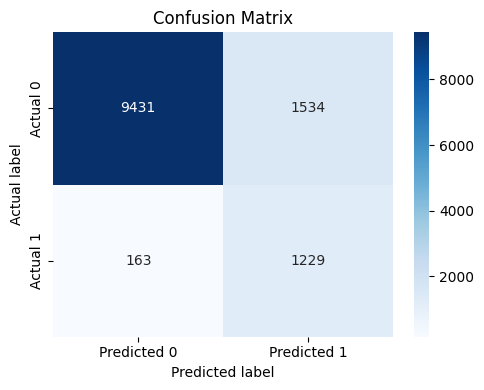

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()


Confusion matrix terms:
- TN: actual 0 and predicted 0.
- FP: actual 0 but predicted 1.
- FN: actual 1 but predicted 0.
- TP: actual 1 and predicted 1.
For a bank, false positives may mean spending marketing effort on customers who do not subscribe. False negatives mean missing customers who would have subscribed.

ROC curve

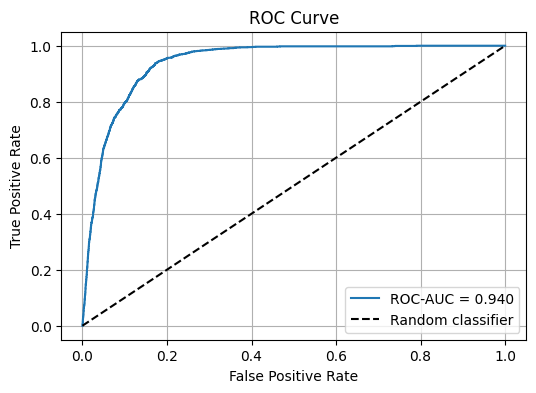

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


Step 11: Calibration and thresholding

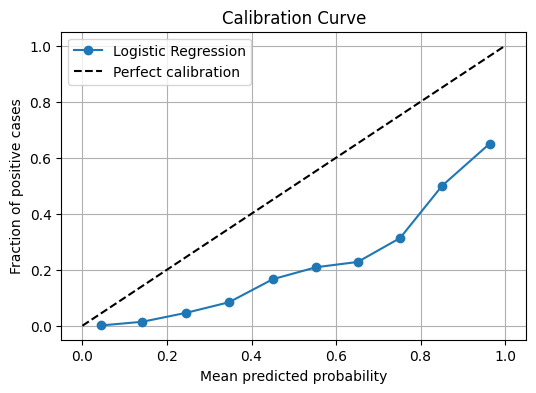

In [ ]:
# Calibration curve: compare predicted probabilities with observed positive rates
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10, strategy="uniform")

plt.figure(figsize=(6, 4))
plt.plot(prob_pred, prob_true, marker="o", label="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positive cases")
plt.title("Calibration Curve")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Example of changing the classification threshold
threshold = 0.40
y_pred_threshold = (y_proba >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy :", round(accuracy_score(y_test, y_pred_threshold), 4))
print("Precision:", round(precision_score(y_test, y_pred_threshold, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_threshold, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred_threshold, zero_division=0), 4))
print("\nConfusion matrix at threshold", threshold, ":\n",
      confusion_matrix(y_test, y_pred_threshold))


Threshold: 0.4
Accuracy : 0.8422
Precision: 0.4112
Recall   : 0.9282
F1-score : 0.5699

Confusion matrix at threshold 0.4 :
 [[9115 1850]
 [ 100 1292]]


Step 12: Save the trained model

In [ ]:
# Save the complete pipeline (preprocessing + Logistic Regression)
joblib.dump(clf_pipeline, "banking_logistic_regression_pipeline.joblib")

print("Model pipeline saved successfully.")


Model pipeline saved successfully.


Step 13: Predict for a single new customer

In [ ]:
# Example customer. Values are illustrative; replace them with real customer data.
sample_customer = pd.DataFrame([{
    "age": 35,
    "job": "admin.",
    "marital": "married",
    "education": "university.degree",
    "default": "no",
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "month": "may",
    "day_of_week": "mon",
    "duration": 200,
    "campaign": 1,
    "pdays": 999,
    "previous": 0,
    "poutcome": "nonexistent",
    "emp_var_rate": 1.1,
    "cons_price_idx": 93.994,
    "cons_conf_idx": -36.4,
    "euribor3m": 4.857,
    "nr_employed": 5191.0
}])

# Predict class and probability
customer_prediction = clf_pipeline.predict(sample_customer)[0]
customer_probability = clf_pipeline.predict_proba(sample_customer)[0, 1]

print("Predicted class:", customer_prediction)
print("Probability of subscription:", round(customer_probability, 4))

if customer_prediction == 1:
    print("Prediction: The customer is likely to subscribe.")
else:
    print("Prediction: The customer is unlikely to subscribe.")


Predicted class: 0
Probability of subscription: 0.0771
Prediction: The customer is unlikely to subscribe.


Final notes / limitations
1. The model predicts patterns in this dataset; it does not guarantee a customer's decision.
2. The dataset is imbalanced, so evaluate minority-class recall and precision carefully.
3. duration is only available after the last contact. For a campaign model intended to select customers before calling them, remove duration from X and retrain.
4. unknown may be a literal category in this dataset rather than a missing value. The initial missing-value check reports actual nulls only.
5. The single-customer example is illustrative, not a real customer's prediction.